In [1]:
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import (classification_report,
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score)

import matplotlib.pyplot as plt

# Classificação (KNN)

In [2]:
x,y = load_breast_cancer(return_X_y=True)

K = [1,3,5,7]

resultados = []

melhor_modelo = None
melhor_acuracia = 0
melhor_nome = ""
melhor_k = None
melhor_X_test = None

In [3]:
# dataset 'cru'
X_train, X_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [4]:
# sem feature scaling
print("SEM FEATURE SCALING")
for k in K:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    # previsões
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # acurácia
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    print(f"\n========== K = {k} ==========")

    print(f"Acurácia treino: {train_accuracy:.4f}")
    print(f"Acurácia teste:  {test_accuracy:.4f}")

    # report de classificação no conjunto de teste
    print("\nRelatório de classificação:")
    print(classification_report(y_test, y_test_pred))
    
    score = model.score(X_test, y_test)
    print(f"K = {k}: {score:.4f}")

    resultados.append({
        "K": k,
        "Scaling": "Sem scaling",
        "Treino": train_accuracy,
        "Teste": test_accuracy
    })

    if test_accuracy > melhor_acuracia:
        melhor_acuracia = test_accuracy
        melhor_modelo = model
        melhor_nome = "Sem scaling"
        melhor_k = k
        melhor_X_test = X_test

SEM FEATURE SCALING

========== K = 1 ==========
Acurácia treino: 1.0000
Acurácia teste:  0.9298

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.95      0.86      0.90        43
           1       0.92      0.97      0.95        71

    accuracy                           0.93       114
   macro avg       0.93      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114

K = 1: 0.9298

========== K = 3 ==========
Acurácia treino: 0.9495
Acurácia teste:  0.9298

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.93      0.88      0.90        43
           1       0.93      0.96      0.94        71

    accuracy                           0.93       114
   macro avg       0.93      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114

K = 3: 0.9298

========== K = 5 ==========
Acurácia treino: 0.9407
Acurácia teste:  0.9561

Relatóri

In [5]:
minmax_scaler = MinMaxScaler()
zscore_scaler = StandardScaler()

X_train_norm = minmax_scaler.fit_transform(X_train)
X_test_norm = minmax_scaler.transform(X_test)

X_train_std = zscore_scaler.fit_transform(X_train)
X_test_std = zscore_scaler.transform(X_test)

In [6]:
# normalizado
print("NORMALIZADO")
for k in K:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_norm, y_train)

    # previsões
    y_train_pred = model.predict(X_train_norm)
    y_test_pred = model.predict(X_test_norm)

    # acurácia
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    print(f"\n========== K = {k} ==========")

    print(f"Acurácia treino: {train_accuracy:.4f}")
    print(f"Acurácia teste:  {test_accuracy:.4f}")

    # report de classificação no conjunto de teste
    print("\nRelatório de classificação:")
    print(classification_report(y_test, y_test_pred))
    
    score = model.score(X_test_norm, y_test)
    print(f"K = {k}: {score:.4f}")

    resultados.append({
        "K": k,
        "Scaling": "Com scaling (normalizado)",
        "Treino": train_accuracy,
        "Teste": test_accuracy
    })

    # Guarda o melhor modelo
    if test_accuracy > melhor_acuracia:
        melhor_acuracia = test_accuracy
        melhor_modelo = model
        melhor_nome = "Normalizado"
        melhor_k = k
        melhor_X_test = X_test_norm

NORMALIZADO

========== K = 1 ==========
Acurácia treino: 1.0000
Acurácia teste:  0.9561

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.93      0.95      0.94        43
           1       0.97      0.96      0.96        71

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114

K = 1: 0.9561

========== K = 3 ==========
Acurácia treino: 0.9868
Acurácia teste:  0.9649

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95        43
           1       0.97      0.97      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114

K = 3: 0.9649

========== K = 5 ==========
Acurácia treino: 0.9758
Acurácia teste:  0.9649

Relatório de cla

In [7]:
# padronizado
print("PADRONIZADO")
for k in K:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_std, y_train)

    # previsões
    y_train_pred = model.predict(X_train_std)
    y_test_pred = model.predict(X_test_std)

    # acurácia
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    print(f"\n========== K = {k} ==========")

    print(f"Acurácia treino: {train_accuracy:.4f}")
    print(f"Acurácia teste:  {test_accuracy:.4f}")

    # report de classificação no conjunto de teste
    print("\nRelatório de classificação:")
    print(classification_report(y_test, y_test_pred))
    
    score = model.score(X_test_std, y_test)
    print(f"K = {k}: {score:.4f}")

    resultados.append({
        "K": k,
        "Scaling": "Com scaling (padronizado)",
        "Treino": train_accuracy,
        "Teste": test_accuracy
    })

    # Guarda o melhor modelo
    if test_accuracy > melhor_acuracia:
        melhor_acuracia = test_accuracy
        melhor_modelo = model
        melhor_nome = "Padronizado"
        melhor_k = k
        melhor_X_test = X_test_std

PADRONIZADO

========== K = 1 ==========
Acurácia treino: 1.0000
Acurácia teste:  0.9386

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92        43
           1       0.94      0.96      0.95        71

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114

K = 1: 0.9386

========== K = 3 ==========
Acurácia treino: 0.9846
Acurácia teste:  0.9474

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        43
           1       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

K = 3: 0.9474

========== K = 5 ==========
Acurácia treino: 0.9802
Acurácia teste:  0.9474

Relatório de cla


RESULTADOS
K= 1 | Sem scaling               | Treino=1.0000 | Teste=0.9298
K= 3 | Sem scaling               | Treino=0.9495 | Teste=0.9298
K= 5 | Sem scaling               | Treino=0.9407 | Teste=0.9561
K= 7 | Sem scaling               | Treino=0.9407 | Teste=0.9561
K= 1 | Com scaling (normalizado) | Treino=1.0000 | Teste=0.9561
K= 3 | Com scaling (normalizado) | Treino=0.9868 | Teste=0.9649
K= 5 | Com scaling (normalizado) | Treino=0.9758 | Teste=0.9649
K= 7 | Com scaling (normalizado) | Treino=0.9714 | Teste=0.9649
K= 1 | Com scaling (padronizado) | Treino=1.0000 | Teste=0.9386
K= 3 | Com scaling (padronizado) | Treino=0.9846 | Teste=0.9474
K= 5 | Com scaling (padronizado) | Treino=0.9802 | Teste=0.9474
K= 7 | Com scaling (padronizado) | Treino=0.9692 | Teste=0.9474

Melhor modelo:
K = 3
Scaling = Normalizado
Acurácia teste = 0.9649

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        43
      benign   

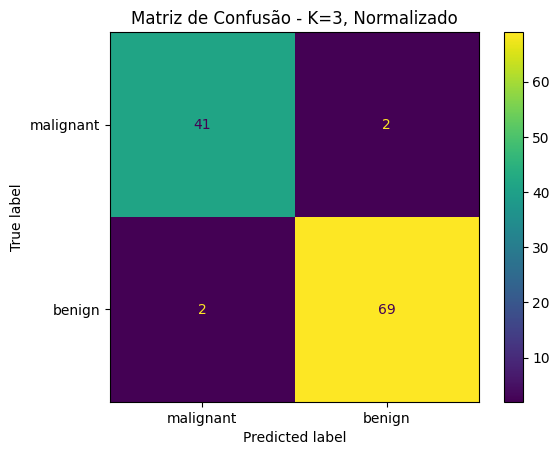

In [8]:
print("\nRESULTADOS")

for resultado in resultados:

    print(
        f"K={resultado['K']:>2} | "
        f"{resultado['Scaling']:<25} | "
        f"Treino={resultado['Treino']:.4f} | "
        f"Teste={resultado['Teste']:.4f}"
    )


print("\nMelhor modelo:")
print(f"K = {melhor_k}")
print(f"Scaling = {melhor_nome}")
print(f"Acurácia teste = {melhor_acuracia:.4f}")


y_pred = melhor_modelo.predict(melhor_X_test)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["malignant", "benign"]
    )
)


# matriz de confusão
cm = confusion_matrix(y_test, y_pred)

print("\nMATRIZ DE CONFUSÃO")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["malignant", "benign"]
)

disp.plot()

plt.title(
    f"Matriz de Confusão - K={melhor_k}, {melhor_nome}"
)

plt.show()

# Regressão

In [9]:
x,y = fetch_california_housing(return_X_y=True)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [11]:
# padronização
standard_scaler = StandardScaler()

X_train_standard = standard_scaler.fit_transform(X_train)
X_test_standard = standard_scaler.transform(X_test)


# mormalização
minmax_scaler = MinMaxScaler()

X_train_minmax = minmax_scaler.fit_transform(X_train)
X_test_minmax = minmax_scaler.transform(X_test)

In [12]:
def avaliar_modelo(modelo, X_train, X_test, y_train, y_test):

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    # treina metricas
    mae_train = mean_absolute_error(y_train, pred_train)
    mse_train = mean_squared_error(y_train, pred_train)
    rmse_train = np.sqrt(mse_train)
    r2_train = r2_score(y_train, pred_train)

    # testa metricas
    mae_test = mean_absolute_error(y_test, pred_test)
    mse_test = mean_squared_error(y_test, pred_test)
    rmse_test = np.sqrt(mse_test)
    r2_test = r2_score(y_test, pred_test)

    return {
        "MAE treino": mae_train,
        "MSE treino": mse_train,
        "RMSE treino": rmse_train,
        "R2 treino": r2_train,

        "MAE teste": mae_test,
        "MSE teste": mse_test,
        "RMSE teste": rmse_test,
        "R2 teste": r2_test
    }

In [13]:
resultados_linear = []

# sem scaling
resultado = avaliar_modelo(
    LinearRegression(),
    X_train,
    X_test,
    y_train,
    y_test
)

resultado["Modelo"] = "Linear"
resultado["Scaling"] = "Sem scaling"

resultados_linear.append(resultado)


# padronizado
resultado = avaliar_modelo(
    LinearRegression(),
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

resultado["Modelo"] = "Linear"
resultado["Scaling"] = "Padronização"

resultados_linear.append(resultado)


# normalizado
resultado = avaliar_modelo(
    LinearRegression(),
    X_train_minmax,
    X_test_minmax,
    y_train,
    y_test
)

resultado["Modelo"] = "Linear"
resultado["Scaling"] = "Normalização"

resultados_linear.append(resultado)

print("REGRESSÃO LINEAR - OK")

# -----------------------------------------

resultados_knn = []
K = [3, 5, 7, 10, 15, 20]

for k in K:
    
    modelo = KNeighborsRegressor(
        n_neighbors=k,
        weights="distance"
    )

    resultado = avaliar_modelo(
        modelo,
        X_train,
        X_test,
        y_train,
        y_test
    )

    resultado["Modelo"] = f"KNN K={k}"
    resultado["Scaling"] = "Sem Scaling"

    resultados_knn.append(resultado)
    

    modelo = KNeighborsRegressor(
        n_neighbors=k,
        weights="distance"
    )

    resultado = avaliar_modelo(
        modelo,
        X_train_standard,
        X_test_standard,
        y_train,
        y_test
    )

    resultado["Modelo"] = f"KNN K={k}"
    resultado["Scaling"] = "Padronização"

    resultados_knn.append(resultado)


    modelo = KNeighborsRegressor(
        n_neighbors=k,
        weights="distance"
    )

    resultado = avaliar_modelo(
        modelo,
        X_train_minmax,
        X_test_minmax,
        y_train,
        y_test
    )

    resultado["Modelo"] = f"KNN K={k}"
    resultado["Scaling"] = "Normalização"

    resultados_knn.append(resultado)

print("KNN REGRESSOR - OK")

REGRESSÃO LINEAR - OK
KNN REGRESSOR - OK


In [14]:
import pandas as pd

resultados = resultados_linear + resultados_knn
df_resultados = pd.DataFrame(resultados)

      Modelo       Scaling  RMSE treino  RMSE teste  R2 treino  R2 teste  \
0     Linear   Sem scaling       0.7197      0.7456     0.6126    0.5758   
1     Linear  Padronização       0.7197      0.7456     0.6126    0.5758   
2     Linear  Normalização       0.7197      0.7456     0.6126    0.5758   
3    KNN K=3   Sem Scaling       0.0000      1.0697     1.0000    0.1268   
4    KNN K=3  Padronização       0.0000      0.6827     1.0000    0.6443   
5    KNN K=3  Normalização       0.0000      0.6548     1.0000    0.6728   
6    KNN K=5   Sem Scaling       0.0000      1.0418     1.0000    0.1718   
7    KNN K=5  Padronização       0.0000      0.6557     1.0000    0.6719   
8    KNN K=5  Normalização       0.0000      0.6327     1.0000    0.6945   
9    KNN K=7   Sem Scaling       0.0000      1.0339     1.0000    0.1842   
10   KNN K=7  Padronização       0.0000      0.6509     1.0000    0.6767   
11   KNN K=7  Normalização       0.0000      0.6236     1.0000    0.7032   
12  KNN K=10

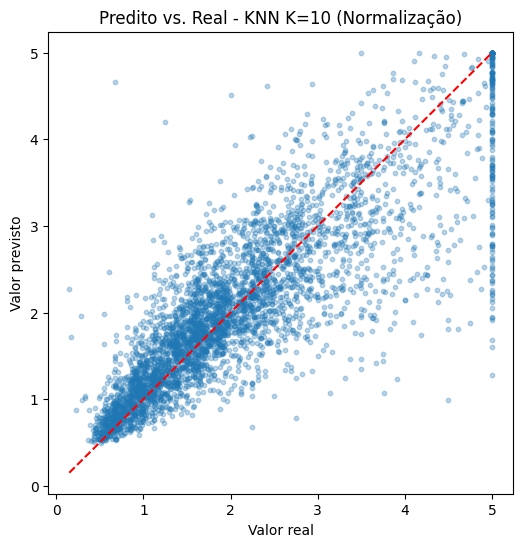

In [15]:
# gap treino-teste para identificar overfitting)
df_resultados["Gap R2"] = df_resultados["R2 treino"] - df_resultados["R2 teste"]

print(df_resultados[["Modelo", "Scaling", "RMSE treino", "RMSE teste",
                     "R2 treino", "R2 teste", "Gap R2"]].round(4))

# melhor modelo = maior R² no teste
melhor = df_resultados.loc[df_resultados["R2 teste"].idxmax()]
print("\nMELHOR MODELO:")
print(melhor[["Modelo", "Scaling", "MAE teste", "RMSE teste",
              "R2 treino", "R2 teste", "Gap R2"]])

# recria o melhor modelo e plota predito vs. real
dados = {
    "Sem scaling": (X_train, X_test),
    "Padronização": (X_train_standard, X_test_standard),
    "Normalização": (X_train_minmax, X_test_minmax),
}
Xtr, Xte = dados[melhor["Scaling"]]

if melhor["Modelo"] == "Linear":
    modelo = LinearRegression()
else:
    k = int(melhor["Modelo"].split("=")[1])
    modelo = KNeighborsRegressor(n_neighbors=k, weights="distance")

modelo.fit(Xtr, y_train)
pred = modelo.predict(Xte)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Valor real")
plt.ylabel("Valor previsto")
plt.title(f"Predito vs. Real - {melhor['Modelo']} ({melhor['Scaling']})")
plt.show()